In [46]:
import numpy as np
import control as ct
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.signal import cont2discrete

## Problem 1

### Problem 1.1

In [30]:
A = np.array([
    [-1, 1], 
    [1, -1]
])

B = np.array([
    [1],
    [0]
])

In [31]:
print("A shape:\n", A.shape)
print("B shape:\n", B.shape)

A shape:
 (2, 2)
B shape:
 (2, 1)


In [32]:
C = np.array([
    [1, 0]
])

D = np.array([[0]])

In [33]:
print("C shape:\n", C.shape)
print("D shape:\n", D.shape)

C shape:
 (1, 2)
D shape:
 (1, 1)


In [34]:
dt = 0.01

Ad, Bd, Cd, Dd, _ = cont2discrete((A, B, C, D), dt)

In [35]:
print("PROBLEM 1.1\n")

print(f"Sampling time dt = {dt}")
print("\nAd =\n", Ad)
print("\nBd =\n", Bd)
print("\nCd =\n", Cd)
print("\nDd =\n", Dd)

PROBLEM 1.1

Sampling time dt = 0.01

Ad =
 [[0.99009934 0.00990066]
 [0.00990066 0.99009934]]

Bd =
 [[9.95033167e-03]
 [4.96683267e-05]]

Cd =
 [[1 0]]

Dd =
 [[0]]


### Problem 1.2

In [52]:
Q_0 = np.array([[1, 0], [0, 1]])
Q_1 = np.array([[10, 0], [0, 1]])
Q_2 = np.array([[1, 0], [0, 20]])

Q_list = [Q_0, Q_1, Q_2]

R = np.array([[1]])

In [53]:
for i, Q in enumerate(Q_list):
    K_dlqr, _, _ = ct.dlqr(Ad, Bd, Q, R)
    K = -K_dlqr
    print(f"\nFor Q_{i} =\n{Q}\n")
    print(f"Optimal gain K_{i} =\n", K)


For Q_0 =
[[1 0]
 [0 1]]

Optimal gain K_0 =
 [[-0.79384952 -0.6147331 ]]

For Q_1 =
[[10  0]
 [ 0  1]]

Optimal gain K_1 =
 [[-2.50150904 -0.77322409]]

For Q_2 =
[[ 1  0]
 [ 0 20]]

Optimal gain K_2 =
 [[-1.75338413 -2.78895931]]


## Problem 2

### Problem 2.1

In [54]:
T = 20

x_initial = np.array([
    [-0.1, 0.1],
    [-0.1, 0.1]
])

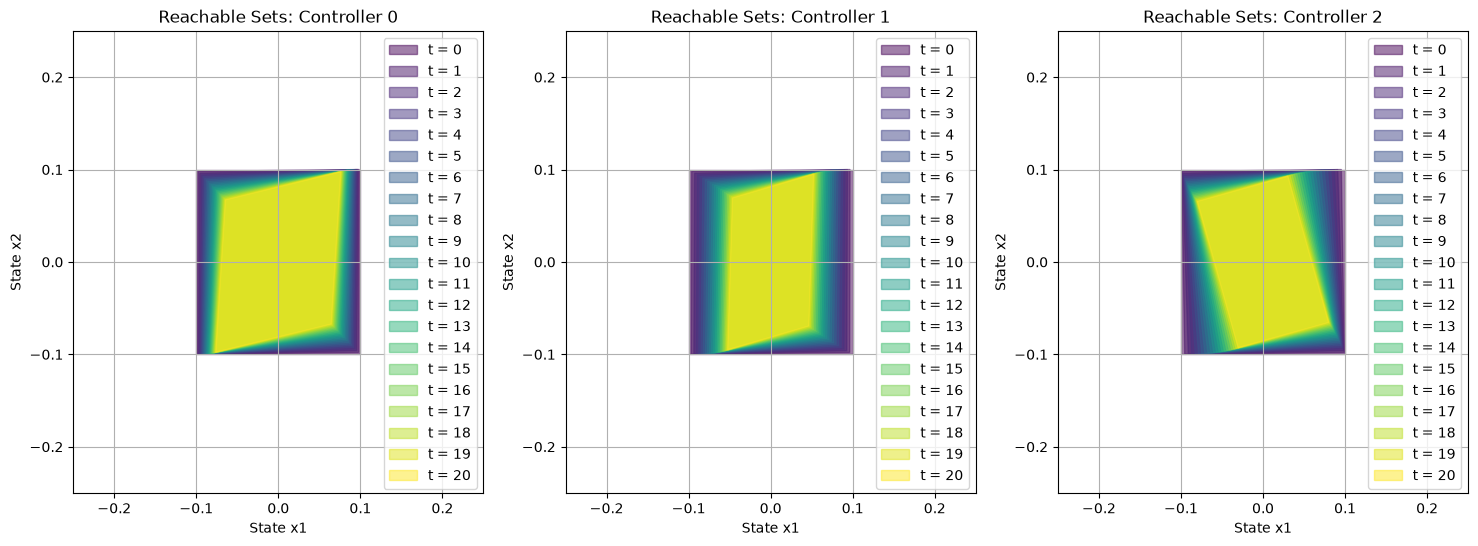

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

colors = plt.cm.viridis(np.linspace(0, 1, T + 1))

for i, Q in enumerate(Q_list):
    K_dlqr, _, _ = ct.dlqr(Ad, Bd, Q, R)
    K = -K_dlqr

    x_vertices = np.zeros((T + 1, 4, 2))

    x_vertices[0] = np.array([
        [x_initial[0, 0], x_initial[1, 0]],
        [x_initial[0, 1], x_initial[1, 0]],
        [x_initial[0, 1], x_initial[1, 1]],
        [x_initial[0, 0], x_initial[1, 1]]
    ])

    for t in range(1, T + 1):
        for v in range(4):
            x_vertices[t, v] = Ad @ x_vertices[t - 1, v] + Bd @ (K @ x_vertices[t - 1, v])

    ax = axes[i]

    for t in range(T + 1):
        polygon = patches.Polygon(
            x_vertices[t], 
            closed=True,
            color=colors[t], 
            alpha=0.5, 
            label=f't = {t}'
        )
        ax.add_patch(polygon)

    x_values = x_vertices[:, :, 0]
    y_values = x_vertices[:, :, 1]

    x_min, x_max = x_values.min(), x_values.max()
    y_min, y_max = y_values.min(), y_values.max()

    ax.set_xlim(x_min - 0.15, x_max + 0.15)
    ax.set_ylim(y_min - 0.15, y_max + 0.15)

    ax.set_title(f"Reachable Sets: Controller {i}")
    ax.set_xlabel("State x1")
    ax.set_ylabel("State x2")
    ax.legend()
    ax.grid(True)


plt.show()